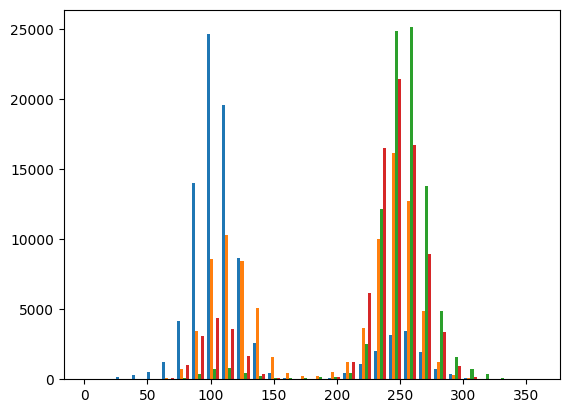

In [1]:
import copy
import pickle
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


ps_cmd = pickle.load(open(f"./pickle-cache/sugar-puckering/ps_cmd.pickle", "rb"))
ps_cmd_nyny = copy.deepcopy(ps_cmd[11:15].T)
ps_cmd_nyny += 90
ps_cmd_nyny %= 360
plt.hist(ps_cmd_nyny, bins=30)

metastabled_trajs_concat = pickle.load(open("./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))

x = ps_cmd_nyny
y = metastabled_trajs_concat
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import classification_report
import os


clf = RandomForestClassifier(
    n_estimators=100,
    random_state=0,
    class_weight="balanced",
    n_jobs=12,
)
clf.fit(x_train, y_train)

proba = clf.predict_proba(x_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, proba)

f1 = 2 * precision * recall / (precision + recall)
best_threshold = thresholds[f1[:-1].argmax()]
best_threshold = 0.5

y_proba = clf.predict_proba(x_test)[:, 1]
y_pred_adj = (y_proba > best_threshold).astype(int)

print(best_threshold)
print(classification_report(y_test, y_pred_adj))

y_proba_all = clf.predict_proba(x)[:, 1]
y_pred_adj_all = (y_proba_all > best_threshold).astype(int)

pickle_dir = "./pickle-cache/sugar-puckering_classification"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)
pickle.dump(y_pred_adj_all, open(f"{pickle_dir}/y_pred_adj_all.pickle", "wb"))

0.5
              precision    recall  f1-score   support

         0.0       0.72      0.51      0.60      5016
         1.0       0.83      0.92      0.87     12984

    accuracy                           0.81     18000
   macro avg       0.77      0.72      0.74     18000
weighted avg       0.80      0.81      0.80     18000



In [3]:
feature_names = ["A12", "U13", "U14", "C15"]

importances = clf.feature_importances_
for name, imp in zip(feature_names, importances):
    print(f"{name}: {imp:.3f}")

A12: 0.273
U13: 0.288
U14: 0.187
C15: 0.252


In [4]:
from sklearn.inspection import permutation_importance


result = permutation_importance(clf, x_test, y_test, n_repeats=20)
for name, imp in zip(feature_names, result.importances_mean):
    print(f"{name}: {imp:.3f}")

A12: 0.033
U13: 0.095
U14: 0.015
C15: 0.089


In [5]:
nucls = ["AUUC", "AAUC", "ACUC", "AGUC", "AUAC", "AUCC", "AUGC", "AUUA", "AUUG", "AUUU", "CUUC", "GUUC", "UUUC"]

ps_complex_mut = pickle.load(open(f"./pickle-cache/sugar-puckering_mut/ps_complex.pickle", "rb"))
for nucl in nucls:
    print(nucl)
    ps_nyny = copy.deepcopy(ps_complex_mut[nucl][11:15].T)
    ps_nyny += 90
    ps_nyny %= 360
    _x = ps_nyny

    y_proba_all = clf.predict_proba(_x)[:, 1]
    y_pred_adj_all = (y_proba_all > best_threshold).astype(int)
    pickle.dump(y_pred_adj_all, open(f"./pickle-cache/sugar-puckering_classification/y_pred_adj_all_{nucl}.pickle", "wb"))

AUUC
AAUC
ACUC
AGUC
AUAC
AUCC
AUGC
AUUA
AUUG
AUUU
CUUC
GUUC
UUUC
